# 6. Hafta | Kendi Projemin Veri Analizi

**Proje:** Öğrenci Akademik Başarısını Etkileyen Faktörlerin Veri Analizi ve Makine Öğrenmesi ile İncelenmesi
**Grup/Ekip:** Bireysel çalışma (Kehribal Öztürk) • **Ders:** Araştırma Yöntem ve Teknikleri – Marmara Üniversitesi UZEM

## A. Veri tanıtımı
- **Veri seti:** UCI Machine Learning Repository – *Student Performance* (`student-mat.csv`, matematik dersi). https://archive.ics.uci.edu/dataset/320/student+performance
- **Kaynak / lisans:** Cortez, P. (2014). Student Performance. UCI Machine Learning Repository. DOI: https://doi.org/10.24432/C5TG7T • **CC BY 4.0**
- **Biçim:** CSV (ayraç `;`). **Gerçek, açık erişimli** veridir; gerçek gözlem verileridir. Açık kaynaklı veri kümesi tercih edilmiştir.
- **Satır / sütun:** Her satır bir öğrenci; 395 gözlem, 33 değişken (demografik, sosyal, okul ve not bilgileri).
- **Ölçü birimleri:** `G1`, `G2`, `G3` 0–20 not puanı; `absences` ders devamsızlığı (gün/ders sayısı); `studytime` 1–4 ordinal ölçek; `age` yıl.
- **Erişim tarihi:** 15.11.2026

## B. Veriyi okuma (CSV)

In [1]:
import io, zipfile, urllib.request
from pathlib import Path
import pandas as pd

# Veri: UCI Student Performance (Cortez, 2014) - DOI: 10.24432/C5TG7T - Lisans: CC BY 4.0
CSV = Path("../data/student-mat.csv")
if not CSV.exists():
    CSV = Path("student-mat.csv")
if not CSV.exists():  # Colab'da dosya yoksa resmi UCI adresinden indir
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    z1 = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    z2 = zipfile.ZipFile(io.BytesIO(z1.read("student.zip")))
    CSV.write_bytes(z2.read("student-mat.csv"))
veri = pd.read_csv(CSV, sep=";")
print("Boyut (satır, sütun):", veri.shape)
veri.head()

Boyut (satır, sütun): (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## C. Veri inceleme ve hesaplama (toplam, ortalama, minimum, maksimum)

In [2]:
print("Eksik değer toplamı:", int(veri.isna().sum().sum()))
sayisal = ["age", "studytime", "failures", "absences", "G1", "G2", "G3"]   # 7 sayısal değişken
ozet = veri[sayisal].agg(["sum", "mean", "min", "max"]).round(2)
ozet

Eksik değer toplamı: 0


,age,studytime,failures,absences,G1,G2,G3
sum,6595.0,804.00,132.00,2255.00,4309.00,4232.00,4114.00
mean,16.7,2.04,0.33,5.71,10.91,10.71,10.42
min,15.0,1.00,0.00,0.00,3.00,0.00,0.00
max,22.0,4.00,3.00,75.00,19.00,19.00,20.00


**Okuma:** Dönem notlarının ortalaması G1 = 10,91, G2 = 10,71 ve G3 = 10,42'dir (0–20 puan). Ortalama not dönemler ilerledikçe hafifçe düşmektedir. `absences` değişkeninin maksimumu 75'tir; ortalamanın (5,71) çok üstünde olduğundan uç değer içerir.

In [3]:
from pathlib import Path
OUT = Path("../outputs") if Path("../outputs").exists() else Path("outputs")
OUT.mkdir(exist_ok=True)
ozet.to_csv(OUT / "hafta6_betimsel_istatistik.csv")
print("Kaydedildi:", OUT / "hafta6_betimsel_istatistik.csv")

Kaydedildi: ..\outputs\hafta6_betimsel_istatistik.csv


## D. Sütun grafiği: Haftalık çalışma süresi grubuna göre ortalama final notu

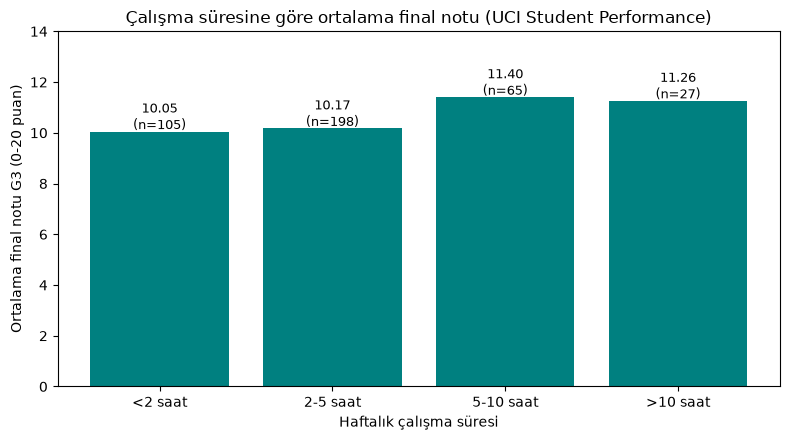

,mean,count
studytime,,
<2 saat,10.05,105
2-5 saat,10.17,198
5-10 saat,11.40,65
>10 saat,11.26,27


In [4]:
import matplotlib.pyplot as plt
etiket = {1: "<2 saat", 2: "2-5 saat", 3: "5-10 saat", 4: ">10 saat"}
g = veri.groupby("studytime")["G3"].agg(["mean", "count"]).rename(index=etiket)
fig, ax = plt.subplots(figsize=(8, 4.5))
cubuk = ax.bar(g.index, g["mean"], color="teal")
for c, n in zip(cubuk, g["count"]):
    ax.text(c.get_x() + c.get_width()/2, c.get_height() + 0.1, f"{c.get_height():.2f}\n(n={n})", ha="center", fontsize=9)
ax.set_xlabel("Haftalık çalışma süresi")
ax.set_ylabel("Ortalama final notu G3 (0-20 puan)")
ax.set_title("Çalışma süresine göre ortalama final notu (UCI Student Performance)")
ax.set_ylim(0, 14)
fig.tight_layout(); fig.savefig(OUT / "hafta6_sutun_grafigi.png", dpi=160); plt.show()
g.round(2)

## E. Çizgi grafiği: Dönemler boyunca ortalama not (G1 → G2 → G3)

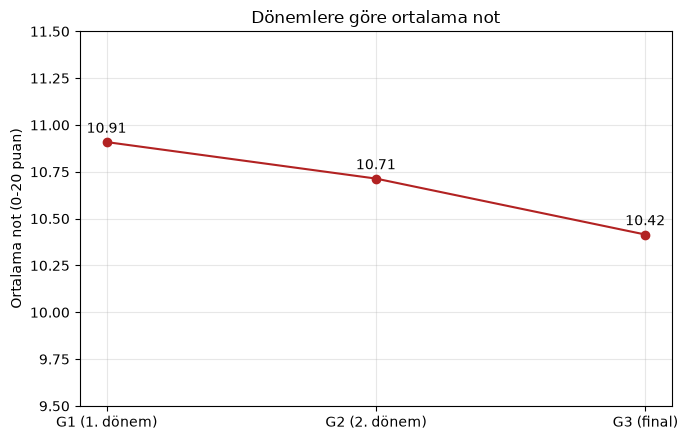

In [5]:
ort = veri[["G1", "G2", "G3"]].mean()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(["G1 (1. dönem)", "G2 (2. dönem)", "G3 (final)"], ort.values, marker="o", color="firebrick")
for i, v in enumerate(ort.values):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylabel("Ortalama not (0-20 puan)")
ax.set_title("Dönemlere göre ortalama not")
ax.set_ylim(9.5, 11.5); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "hafta6_cizgi_grafigi.png", dpi=160); plt.show()

In [6]:
veri[sayisal].to_csv(OUT / "hafta6_kullanilan_veri.csv", index=False)
veri[sayisal].head().to_json(OUT / "hafta6_ornek.json", orient="records", force_ascii=False, indent=2)
print("CSV ve JSON çıktıları kaydedildi.")

CSV ve JSON çıktıları kaydedildi.


## F. Akademik yorum
**Veri kaynağı ve değişken:** Analiz, UCI Student Performance veri setinin matematik dersi kısmına (395 öğrenci) dayanır; birimler 0–20 not puanı, 1–4 ordinal çalışma süresi ve devamsızlık sayısıdır.

**Toplam / ortalama ve birimler:** Ortalama final notu 10,42/20'dir; en düşük 0, en yüksek 20'dir. Ortalama devamsızlık 5,71 olup en yüksek değer 75'tir.

**Grafikte görülen bulgu:** Haftalık çalışma süresi arttıkça ortalama final notu genel olarak artmaktadır (<2 saat: 10,05; 5–10 saat: 11,40). Ancak ">10 saat" grubunda (n = 27) ortalama 11,26 ile hafifçe düşer; bu grup küçüktür. Dönemler ilerledikçe ortalama not 10,91'den 10,42'ye düşmektedir.

**Sınırlılıklar ve ölçemediği şeyler:** Çalışma süresi öğrenci beyanına dayalı ve kategoriktir; grup büyüklükleri eşit değildir. Veri iki Portekiz okulundan gelir ve Türkiye'ye genellenemez. Grafikteki ilişki tek başına neden–sonuç kanıtı değildir.

**Ekipçe yapılan işlem:** Bireysel çalışma; veri okuma, hesaplama, grafik ve yorum tek kişi tarafından yapılmıştır.

> Hiçbir kişisel veri, API anahtarı veya parola kullanılmamıştır.

## G. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası
- [x] CSV/JSON çıktısı ve yasal, erişilebilir veri kaynağı
- [x] Birim + veri kaynağı + lisans
- [x] Açıklamalı sütun ve çizgi grafiği
- [x] Toplam ve ortalama hesabı
- [x] 4-5 cümlelik yorum
- [x] README içinde katkı
- [ ] GitHub repo bağlantısı (README'ye eklenecek)
- [x] Gizli/kişisel veri ve anahtar yok